# LLM агент с RAG системой для анализа таблиц с данными

Задача:
Разработка AI-агента аналитика данных для при первичном анализе данных, автоматизации создания графиков, получение структурированного отчета о данных для людей, которые не сильны в программировании и аналитике или для тех у кого нет на просмотр данных нет столько времени

Решение:
Создать агента с инструментами для построения графика, проверки гипотез по критериям, проведении корреляционного анализа, доуточнения в системе RAG. В самой же RAG разместить иформацию о работе аналитика данных, проведении корреляционного анализа, тестировании различных гипотез, вывод информации из векторной БД сделать двухэтапным: BM25 (лексический) + векторный поиск (семантический)

## Импорт библиотек и определение состояний

Для реализации агента и графа сценария возьмем библиотеки langchain и langgraph. В реализации инструментв возьмем стандартные для data science инструменты pandas, numpy, scipy, plotly. Ну и дополниельно некоторые утилитарные библиотеки.

In [1]:
import os
from pathlib import Path
import markdown as md_lib
from datetime import datetime
import re

from typing import Annotated, TypedDict, Optional
from langgraph.graph.message import add_messages

import pandas as pd
import numpy as np
from scipy import stats
import plotly.express as px
import plotly.graph_objects as go
from langchain_core.tools import tool
from langgraph.prebuilt import InjectedState

from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS
from rank_bm25 import BM25Okapi
from sentence_transformers import CrossEncoder

from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langgraph.prebuilt import tools_condition

GRAPHICS_DIR = Path("graphics")
GRAPHICS_DIR.mkdir(exist_ok=True)

C:\Users\User\anaconda3\envs\work_ml\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\User\anaconda3\envs\work_ml\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (
C:\Users\User\AppData\Local\Temp\ipykernel_24012\624785591.py:18: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


Теперь определим что будет хранится в Состоянии. Как минимум нам нужно хранить пути до папок с данными, файлами для RAG, путь для итогового отчета. Потом для аналитики будет нужно история вызовов и результаты работы, ну и конечно чанки из RAG для более реливантного ответа. 

Итого у нас будет такой State:
- история диалога
- путь к данным
- краткое описание данных
- результаты инструментов
- пути к сохранённым графикам
- найденные чанки из RAG
- итоговый отчёт
- путь к финальному отчету

In [2]:
class AgentState(TypedDict):
    messages: Annotated[list, add_messages]  # история диалога
    dataframe_path: str                       # путь к CSV
    dataframe_summary: str                    # краткое описание данных
    analysis_results: list[dict]              # результаты инструментов
    charts: list[str]                         # пути к сохранённым графикам
    rag_context: list[str]                    # найденные чанки из RAG
    final_report: str                         # итоговый отчёт
    report_path: str                          # путь к финальному отчету

STATE = {}
STATE["dataframe_path"] = "sale_data.csv"

## Построение двухэтапной RAG системы

Класс RAGPipeline строит RAG-поиск по PDF: при инициализации он загружает эмбеддинги bge-m3 и кросс-энкодер bge-reranker-v2-m3, затем читает PDF-файлы постранично, добавляет метаданные источника и страницы, разбивает текст на чанки по 800 символов с перекрытием 150 и создаёт два индекса — векторный FAISS для семантического поиска и лексический BM25 для поиска по точным словам; в методе search запрос сначала ищется параллельно в обоих индексах, результаты объединяются через Reciprocal Rank Fusion, при необходимости фильтруются по отрасли и минимальному году, после чего кандидаты переранжируются кросс-энкодером и возвращаются top-k фрагментов с текстом, метаданными и оценкой. Главные преимущества — сочетание семантического и лексического поиска (лучше находит и перефразировки, и точные термины/аббревиатуры), RRF-объединение устойчивее к разной шкале оценок, cross-encoder rerank повышает точность выдачи, а фильтрация по метаданным позволяет учитывать отрасль и год.

In [3]:
class RAGPipeline:
    def __init__(self, pdf_paths: list[str]):
        self.embeddings = HuggingFaceEmbeddings(model_name="seansitter/bge-m3-safetensors")
        self.reranker = CrossEncoder("BAAI/bge-reranker-v2-m3")
        self._build_index(pdf_paths)

    def _build_index(self, pdf_paths):
        docs = []
        for path in pdf_paths:
            loader = PyPDFLoader(path)
            pages = loader.load()
            for i, page in enumerate(pages):
                page.metadata["source"] = path.split("/")[-1]
                page.metadata["page"] = i + 1
            docs.extend(pages)

        splitter = RecursiveCharacterTextSplitter(
            chunk_size=800, chunk_overlap=150
        )
        self.chunks = splitter.split_documents(docs)

        # Векторный индекс (FAISS)
        self.vectorstore = FAISS.from_documents(self.chunks, self.embeddings)

        # Лексический индекс (BM25)
        self.bm25_corpus = [c.page_content for c in self.chunks]
        self.bm25 = BM25Okapi([doc.split() for doc in self.bm25_corpus])

    def search(self, query: str, k: int = 5, industry: str = None,
               year_min: int = None, top_k_retrieval: int = 50) -> list[dict]:
        # ── Этап 1: Гибридный retrieval ──
        # Векторный поиск
        vector_results = self.vectorstore.similarity_search_with_score(
            query, k=top_k_retrieval
        )

        # BM25
        bm25_scores = self.bm25.get_scores(query.split())
        bm25_top = np.argsort(bm25_scores)[::-1][:top_k_retrieval]
        bm25_results = [
            (self.chunks[i], bm25_scores[i]) for i in bm25_top
        ]

        # RRF fusion
        fused = self._rrf_fusion(vector_results, bm25_results, top_k=top_k_retrieval)

        # Фильтрация по метаданным
        if industry:
            fused = [c for c in fused if industry.lower() in
                     c[0].metadata.get("industry", "").lower()]
        if year_min:
            fused = [c for c in fused if c[0].metadata.get("year", 0) >= year_min]

        # ── Этап 2: Cross-encoder rerank ──
        pairs = [(query, chunk.page_content) for chunk, _ in fused]
        rerank_scores = self.reranker.predict(pairs)
        reranked = sorted(
            zip([c for c, _ in fused], rerank_scores),
            key=lambda x: x[1], reverse=True
        )

        return [
            {"text": chunk.page_content, "metadata": chunk.metadata, "score": score}
            for chunk, score in reranked[:k]
        ]

    @staticmethod
    def _rrf_fusion(list1, list2, top_k=50, k=60):
        """Reciprocal Rank Fusion для объединения векторного и лексического поиска."""
        scores = {}
        for rank, (doc, _) in enumerate(list1):
            scores[doc.page_content] = scores.get(doc.page_content, 0) + 1 / (k + rank + 1)
            scores[doc.page_content + "_doc"] = doc

        for rank, (doc, _) in enumerate(list2):
            key = doc.page_content
            scores[key] = scores.get(key, 0) + 1 / (k + rank + 1)
            if key + "_doc" not in scores:
                scores[key + "_doc"] = doc

        ranked = sorted(
            [(k, v) for k, v in scores.items() if not k.endswith("_doc")],
            key=lambda x: x[1], reverse=True
        )
        return [(scores[k + "_doc"], v) for k, v in ranked[:top_k]]


Теперь создадим БД поместив туда найденные материалы. В матриалы я положил 4 файла, которые смог найти:
- статья про корреляционный анализ
- методика проведения исследовательского анализа данных
- как проводятся гипотезы
- поиск инсайтов в данных

In [4]:
RAG_PIPELINE = RAGPipeline([
    "research/correlation.pdf",
    "research/eda.pdf",
    "research/hipotesis.pdf",
    "research/insigth.pdf"
])

C:\Users\User\AppData\Local\Temp\ipykernel_24012\2282819119.py:3: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the `langchain-huggingface package and should be used instead. To use it run `pip install -U `langchain-huggingface` and import as `from `langchain_huggingface import HuggingFaceEmbeddings``.
  self.embeddings = HuggingFaceEmbeddings(model_name="seansitter/bge-m3-safetensors")


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

## Добавление агенту инструментов и создание графа через LangGraph


Для задуманной идеи работы требуются следующие инструменты:
1) profile_dataframe(path) — загружает CSV и возвращает базовый EDA: размер, типы колонок, пропуски и описательные статистики
2) run_stat_test(test_type, col1, col2) — выполняет статтест: ttest, chi2, shapiro, pearson; возвращает статистику, p-value и интерпретацию значимости при α=0.05
3) make_chart(chart_type, x, y, agg, title, top_n) — строит график (line, bar, scatter, histogram, box), умеет агрегировать (sum/mean/count/median) и брать топ-N категорий, сохраняет в HTML с единым стилем
4) search_research(query, industry, year_min) — двухступенчатый поиск по RAG-базе: гибридный retrieval (BM25 + FAISS, top-50) → cross-encoder rerank (top-5); возвращает фрагменты с указанием источника и страницы, с опциональными фильтрами по отрасли и году
5) correlation_matrix(columns, method, min_abs_corr, title) — считает корреляционную матрицу (pearson/spearman/kendall), добавляет p-value и звёздочки значимости, строит интерактивный heatmap с маской верхнего треугольника и порогом |r|; в текстовом отчёте выделяет топ-5 связей и предупреждает о мультиколлинеарности (|r| > 0.8)r| > 0.8

In [5]:
def _save_chart(fig, name: str) -> str:
    """Сохраняет график как фрагмент (без <html>, без plotly.js)."""
    path = GRAPHICS_DIR / name
    fig.write_html(
        str(path),
        full_html=False,          # только <div> + <script>
        include_plotlyjs=False,   # plotly.js подключим в финальном отчёте
    )
    return str(path)

# ─── Инструмент 1: Загрузка и профилирование данных ───
@tool
def profile_dataframe(path: str) -> str:
    """Загружает CSV и возвращает базовый EDA: типы, пропуски, описательные статистики."""
    df = pd.read_csv(STATE["dataframe_path"])
    info = {
        "shape": df.shape,
        "columns": df.dtypes.astype(str).to_dict(),
        "missing": df.isnull().sum().to_dict(),
        "describe": df.describe().to_dict(),
    }
    return str(info)


# ─── Инструмент 2: Статистический тест ───
@tool
def run_stat_test(test_type: str, col1: str, col2: str = None) -> str:
    """
    Выполняет статистический тест.
    test_type: 'ttest', 'chi2', 'shapiro', 'pearson'
    col1, col2: имена колонок
    """
    df = pd.read_csv(STATE["dataframe_path"])
    if test_type == "shapiro":
        stat, p = stats.shapiro(df[col1].dropna())
    elif test_type == "pearson":
        stat, p = stats.pearsonr(df[col1], df[col2])
    elif test_type == "ttest":
        stat, p = stats.ttest_ind(df[col1], df[col2])
    elif test_type == "chi2":
        contingency = pd.crosstab(df[col1], df[col2])
        stat, p, _, _ = stats.chi2_contingency(contingency)
    else:
        return f"Неизвестный тест: {test_type}"

    interpretation = "значимо" if p < 0.05 else "не значимо"
    return f"{test_type} между {col1} и {col2}: stat={stat:.4f}, p={p:.4f} → результат {interpretation} (α=0.05)"


# ─── Инструмент 3: Построение графика ───
@tool
def make_chart(
    chart_type: str,
    x: str,
    y: str = None,
    agg: str = "sum",
    title: str = "",
    top_n: int = 15,
) -> str:
    """
    Строит график и сохраняет в HTML.

    chart_type: 'line' | 'bar' | 'scatter' | 'histogram' | 'box'
    x, y: имена колонок
    agg: агрегация при группировке — 'sum' | 'mean' | 'count' | 'median'
    top_n: оставить только топ-N категорий (по убыванию y)
    """
    plot_df = pd.read_csv(STATE["dataframe_path"])

    # ── Умная агрегация ──
    if chart_type in ("bar", "line") and y:
        agg_func = {"sum": "sum", "mean": "mean",
                    "count": "count", "median": "median"}[agg]
        plot_df = plot_df.groupby(x, as_index=False)[y].agg(agg_func)

    if chart_type == "histogram":
        fig = px.histogram(plot_df, x=x, title=title or f"Распределение {x}")
        fig.update_traces(marker_line_width=1, marker_line_color="white")

    elif chart_type == "bar" and y:
        # Сортировка + top-N
        plot_df = plot_df.sort_values(y, ascending=False).head(top_n)
        plot_df = plot_df.sort_values(y)  # для горизонтального вида
        fig = px.bar(
            plot_df, x=y, y=x, orientation="h",
            title=title or f"{y} по {x} (топ-{top_n})",
            text=y,
            color=y,
            color_continuous_scale="Blues",
        )
        fig.update_traces(texttemplate="%{text:,.0f}", textposition="outside")
        fig.update_layout(coloraxis_showscale=False)
        fig.update_xaxes(title=y, showgrid=True, gridcolor="#EEE")
        fig.update_yaxes(title="")

    elif chart_type == "line" and y:
        plot_df = plot_df.sort_values(x)
        fig = px.line(
            plot_df, x=x, y=y, markers=True,
            title=title or f"{y} во времени ({x})",
        )
        fig.update_traces(line_width=2.5, marker_size=6)
        fig.update_xaxes(tickangle=-45, showgrid=False)

    elif chart_type == "scatter" and y:
        fig = px.scatter(
            plot_df, x=x, y=y,
            title=title or f"{x} vs {y}",
            opacity=0.7, 
        )

    elif chart_type == "box" and y:
        fig = px.box(plot_df, x=x, y=y, title=title or f"Распределение {y} по {x}")
        fig.update_xaxes(tickangle=-45)

    else:
        return f"Не могу построить {chart_type} без колонки y"

    # ── Единый стиль ──
    fig.update_layout(
        template="plotly_white",
        title=dict(x=0.5, xanchor="center", font=dict(size=18)),
        font=dict(family="Inter, Arial", size=13),
        margin=dict(l=80, r=40, t=80, b=80),
        hoverlabel=dict(bgcolor="white", font_size=12),
    )

    path = _save_chart(fig, f"chart_{chart_type}_{x}_{y or 'single'}.html")
    return f"График сохранён: {path}"


# ─── Инструмент 4: Поиск в RAG (двухступенчатый) ───
@tool
def search_research(query: str, industry: str = None, year_min: int = None) -> str:
    """
    Ищет инсайты в базе рыночных исследований.
    Двухступенчатый поиск: гибридный retrieval → cross-encoder rerank.
    """
    # Этап 1: гибридный поиск (BM25 + FAISS) → top-50
    # Этап 2: cross-encoder rerank → top-5
    results = RAG_PIPELINE.search(query, industry=industry, year_min=year_min, k=5)
    return "\n\n---\n\n".join([
        f"[{r['metadata']['source']}, стр. {r['metadata']['page']}]\n{r['text']}"
        for r in results
    ])

# ─── Инструмент 5: Корреляционный анализ ───
@tool
def correlation_matrix(
    columns: Optional[list[str]] = None,
    method: str = "pearson",
    min_abs_corr: float = 0.0,
    title: str = "",
) -> str:
    """
    Считает корреляционную матрицу и сохраняет интерактивный heatmap в HTML.

    columns: список колонок для анализа. Если None — берутся все числовые.
    method: 'pearson' | 'spearman' | 'kendall'.
            pearson — линейная связь (требует нормальности),
            spearman — монотонная (устойчив к выбросам),
            kendall — для маленьких выборок и порядковых данных.
    min_abs_corr: отфильтровать пары с |r| ниже порога (0 — показать все).
    title: заголовок графика (опционально).
    """
    df = pd.read_csv(STATE["dataframe_path"])
    # ── 1. Выбор колонок ──
    if columns is None:
        numeric_df = df.select_dtypes(include=[np.number])
        cols = list(numeric_df.columns)
    else:
        missing = [c for c in columns if c not in df.columns]
        if missing:
            return f"Колонки не найдены: {missing}"
        non_numeric = [c for c in columns
                       if not pd.api.types.is_numeric_dtype(df[c])]
        if non_numeric:
            return (f"Колонки не числовые: {non_numeric}. "
                    f"Для категориальных используй Cramér's V или χ².")
        cols = columns
        numeric_df = df[cols]

    if len(cols) < 2:
        return "Нужно минимум 2 числовые колонки для корреляционной матрицы."

    # ── 2. Сама корреляция ──
    corr = numeric_df.corr(method=method)

    # ── 3. p-values (только для pearson/spearman) ──
    pvals = pd.DataFrame(
        np.ones_like(corr, dtype=float),
        index=corr.index, columns=corr.columns,
    )
    if method in ("pearson", "spearman"):
        for i, c1 in enumerate(cols):
            for j, c2 in enumerate(cols):
                if i >= j:
                    continue
                x = numeric_df[c1].dropna()
                y = numeric_df[c2].dropna()
                common = numeric_df[[c1, c2]].dropna()
                if len(common) < 3:
                    continue
                try:
                    if method == "pearson":
                        _, p = stats.pearsonr(common[c1], common[c2])
                    else:
                        _, p = stats.spearmanr(common[c1], common[c2])
                    pvals.loc[c1, c2] = p
                    pvals.loc[c2, c1] = p
                except Exception:
                    pass

    # ── 4. Фильтрация по порогу (опционально) ──
    if min_abs_corr > 0:
        mask = (corr.abs() >= min_abs_corr) | (corr == 1.0)
        corr = corr.where(mask)
        pvals = pvals.where(mask)

    # ── 5. Текст для аннотаций: r + звёздочки значимости ──
    def fmt_value(r, p):
        if pd.isna(r):
            return ""
        stars = ""
        if method in ("pearson", "spearman") and not pd.isna(p):
            if p < 0.001:
                stars = "***"
            elif p < 0.01:
                stars = "**"
            elif p < 0.05:
                stars = "*"
        return f"{r:.2f}{stars}"

    text = [[fmt_value(corr.iloc[i, j], pvals.iloc[i, j])
             for j in range(len(cols))]
            for i in range(len(cols))]

    # ── 6. Маска верхнего треугольника ──
    mask_upper = np.triu(np.ones_like(corr, dtype=bool), k=1)
    corr_masked = corr.mask(mask_upper)
    text_masked = np.where(mask_upper, "", text)

    # ── 7. Построение heatmap ──
    fig = go.Figure(data=go.Heatmap(
        z=corr_masked.values,
        x=cols,
        y=cols,
        text=text_masked,
        texttemplate="%{text}",
        textfont={"size": 12, "family": "Inter, Arial"},
        colorscale="RdBu_r",
        zmin=-1, zmax=1, zmid=0,
        colorbar=dict(
            title=f"{method} r",
            ticks="outside",
            tickvals=[-1, -0.5, 0, 0.5, 1],
        ),
        hovertemplate=(
            "<b>%{y}</b> ↔ <b>%{x}</b><br>"
            "r = %{z:.3f}<extra></extra>"
        ),
        xgap=1, ygap=1,
    ))

    # ── 8. Название и стиль ──
    method_ru = {
        "pearson": "Пирсон",
        "spearman": "Спирмен",
        "kendall": "Кендалл",
    }[method]
    default_title = f"Корреляционная матрица ({method_ru})"
    if min_abs_corr > 0:
        default_title += f" — |r| ≥ {min_abs_corr}"

    fig.update_layout(
        title=dict(
            text=title or default_title,
            x=0.5, xanchor="center",
            font=dict(size=18),
        ),
        template="plotly_white",
        font=dict(family="Inter, Arial", size=13),
        xaxis=dict(side="bottom", tickangle=-45),
        yaxis=dict(autorange="reversed"),
        margin=dict(l=120, r=80, t=90, b=120),
    )

    path = f"corr_{method}_matrix.html"
    path = _save_chart(fig, f"corr_{method}_matrix.html")

    # ── 9. Текстовый отчёт для LLM ──
    report_lines = [f"Корреляционная матрица ({method_ru}):"]

    # Топ-N сильнейших связей, исключая диагональ
    pairs = []
    for i, c1 in enumerate(cols):
        for j, c2 in enumerate(cols):
            if i < j:
                r = corr.loc[c1, c2]
                p = pvals.loc[c1, c2]
                if not pd.isna(r):
                    pairs.append((c1, c2, r, p))
    pairs.sort(key=lambda x: abs(x[2]), reverse=True)

    report_lines.append("\nТоп-5 сильнейших связей:")
    for c1, c2, r, p in pairs[:5]:
        stars = ""
        if method in ("pearson", "spearman"):
            stars = "***" if p < 0.001 else "**" if p < 0.01 \
                    else "*" if p < 0.05 else " (ns)"
        report_lines.append(f"  {c1} ↔ {c2}: r={r:+.3f}{stars}")

    # Сильные корреляции → предупреждение о мультиколлинеарности
    strong = [(c1, c2, r) for c1, c2, r, _ in pairs if abs(r) > 0.8]
    if strong:
        report_lines.append(
            f"\n⚠️ Обнаружена мультиколлинеарность "
            f"(|r| > 0.8): {len(strong)} пар. "
            f"Учти это при регрессионном анализе."
        )

    report_lines.append(f"\nГрафик сохранён: {path}")
    return "\n".join(report_lines)

Наши инструменты создают отдельные графики, сделаем функцию которая собирает все графики из директории и объеденяет их в один цельный документ с выводами. Запускать функцию будем в самом конце графа.

In [6]:
def _build_html_report(
    report_md: str,
    chart_files: list[Path],
    tool_results: list[str],
) -> str:
    """Конвертирует Markdown в HTML и встраивает графики по маркерам."""

    # 1. Markdown → HTML (с поддержкой таблиц и code-блоков)
    report_html = md_lib.markdown(
        report_md,
        extensions=["tables", "fenced_code", "toc"],
    )

    # 2. Заменяем {{CHART: file.html}} на встроенные графики
    used_charts: set[str] = set()

    def _figure_html(filename: str) -> str:
        chart_path = GRAPHICS_DIR / filename
        if not chart_path.exists():
            return (f'<p class="missing-chart">'
                    f'⚠️ График «{filename}» не найден</p>')
        used_charts.add(filename)
        fragment = chart_path.read_text(encoding="utf-8")
        anchor = filename.replace(".", "_").replace(" ", "_")
        return (
            f'<figure class="chart-block" id="{anchor}">'
            f'{fragment}'
            f'<figcaption>{filename}</figcaption>'
            f'</figure>'
        )

    # Съедаем <p>...</p> вокруг маркера целиком
    report_html = re.sub(
        r"<p>\s*\{\{CHART:\s*([^}]+?)\s*\}\}\s*</p>",
        lambda m: _figure_html(m.group(1).strip().strip("'\"")),
        report_html,
    )
    # Маркеры, оказавшиеся в середине абзаца (без <p>) — на всякий случай
    report_html = re.sub(
        r"\{\{CHART:\s*([^}]+?)\s*\}\}",
        lambda m: _figure_html(m.group(1).strip().strip("'\"")),
        report_html,
    )

    # 3. Графики, которые LLM забыл вставить — добавим в приложение
    unused = [c for c in chart_files if c.name not in used_charts]
    appendix = ""
    if unused:
        blocks = []
        for chart_path in unused:
            fragment = chart_path.read_text(encoding="utf-8")
            blocks.append(
                f'<figure class="chart-block">'
                f'{fragment}'
                f'<figcaption>{chart_path.name}</figcaption>'
                f'</figure>'
            )
        appendix = (
            "<hr>"
            "<h2>Приложение: остальные графики</h2>"
            + "".join(blocks)
        )

    # 4. Финальный HTML
    now = datetime.now().strftime("%Y-%m-%d %H:%M")
    tool_results_escaped = (
        "\n".join(tool_results)
        .replace("&", "&amp;")
        .replace("<", "&lt;")
        .replace(">", "&gt;")
    )

    return f"""<!DOCTYPE html>
<html lang="ru">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Аналитический отчёт</title>
    <script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>
    <style>
        :root {{
            --accent: #447adb;
            --bg: #fafafa;
            --text: #1f2328;
            --muted: #6a737d;
            --border: #e1e4e8;
        }}
        * {{ box-sizing: border-box; }}
        body {{
            font-family: -apple-system, "Inter", "Segoe UI", Arial, sans-serif;
            max-width: 1180px;
            margin: 40px auto;
            padding: 0 24px 80px;
            color: var(--text);
            line-height: 1.65;
            background: #fff;
        }}
        h1 {{
            font-size: 2em;
            border-bottom: 3px solid var(--accent);
            padding-bottom: 12px;
            margin-bottom: 8px;
        }}
        h2 {{
            font-size: 1.4em;
            margin-top: 48px;
            padding-top: 8px;
            color: var(--text);
        }}
        h3 {{ font-size: 1.15em; margin-top: 32px; }}
        .meta {{
            color: var(--muted);
            font-size: 0.9em;
            margin-bottom: 32px;
        }}
        table {{
            border-collapse: collapse;
            margin: 20px 0;
            width: 100%;
            font-size: 0.95em;
        }}
        th, td {{
            border: 1px solid var(--border);
            padding: 8px 12px;
            text-align: left;
        }}
        th {{ background: #f3f5f7; font-weight: 600; }}
        tr:nth-child(even) td {{ background: #fafbfc; }}
        code {{
            background: #f3f5f7;
            padding: 2px 6px;
            border-radius: 4px;
            font-family: "JetBrains Mono", Consolas, monospace;
            font-size: 0.9em;
        }}
        pre {{
            background: #f6f8fa;
            padding: 16px;
            border-radius: 6px;
            overflow-x: auto;
            font-size: 0.85em;
        }}
        figure.chart-block {{
            margin: 32px 0;
            padding: 12px;
            border: 1px solid var(--border);
            border-radius: 8px;
            background: var(--bg);
        }}
        figcaption {{
            font-size: 0.85em;
            color: var(--muted);
            text-align: center;
            margin-top: 8px;
        }}
        .missing-chart {{
            color: #c62828;
            font-style: italic;
            padding: 12px;
            background: #ffebee;
            border-radius: 6px;
        }}
        details {{
            margin: 40px 0 0;
            padding: 12px 16px;
            border: 1px solid var(--border);
            border-radius: 6px;
            background: #fafbfc;
        }}
        details summary {{
            cursor: pointer;
            font-weight: 600;
            color: var(--accent);
        }}
        details pre {{
            max-height: 400px;
            overflow-y: auto;
        }}
        hr {{
            border: none;
            border-top: 1px solid var(--border);
            margin: 48px 0 24px;
        }}
    </style>
</head>
<body>
    <h1>Аналитический отчёт</h1>
    <div class="meta">Сгенерировано: {now}</div>

    {report_html}

    {appendix}

    <details>
        <summary>Сырые результаты инструментов ({len(tool_results)} записей)</summary>
        <pre>{tool_results_escaped}</pre>
    </details>
</body>
"""

Создадим все необходимые ноды для графа. Но начнем с инициализации модели, воспользуемся бесплатными моделями из openrouter, указав api ключик из личного кабинета. Передадим агенту все ранее созданные инструменты через bind_tools, пропишем системные промпт и создадим для llm ноду. Помимо системных нод, нам понадобится еще две ноды - нода с вызовом инструментов и ноду с синтезацией полного отчета.

In [14]:
llm = ChatOpenAI(
    openai_api_key="",
    openai_api_base="https://openrouter.ai/api/v1",
    model_name="openrouter/free",
)
llm_with_tools = llm.bind_tools([
    profile_dataframe, run_stat_test, make_chart, search_research, correlation_matrix
])

SYSTEM_PROMPT = """Ты — аналитический агент. У тебя есть инструменты:
- profile_dataframe: загрузить и изучить таблицу
- run_stat_test: провести статистический тест
- make_chart: построить график
- correlation_matrix: построение корреляционной матрицы 
- search_research: поиск информации RAG 

Работай пошагово:
0. Перед каждым этапом исследования уточни в RAG как он проводится через search_research
1. Проведи EDA: изучи данные через profile_dataframe, построй ВСЕ графики, выдели значимые закономерности и аномалии
2. ВАЖНО! Проверь что графики тобой построены, если их нет сделай нужные для отчета графики функцией profile_dataframe
3. Проведи статистические тесты через run_stat_test для проверки различных гипотез, которые могут быть полезны
4. Проведи корреляционный анализ через correlation_matrix
5. Верни структурированный анализ и отчет

Правила для графиков:
- Для категорий — bar с agg='sum', top_n=10
- Для временных рядов — line (только если точек < 50)
- Для распределения — histogram или box
- ВСЕГДА указывай y — график без y бессмысленен

Для анализа связей между переменными используй correlation_matrix.
- Сначала вызывай с method='pearson', если данные похожи на нормальные.
- Если в предыдущих тестах (Shapiro-Wilk) нормальность отвергнута — 
  используй method='spearman'.
- При 10+ числовых колонках ставь min_abs_corr=0.3, чтобы не утонуть в шуме. В осталбных случаях оставь значение равным 0
- Обязательно интерпретируй мультиколлинеарность, если инструмент о ней предупредил.

Не выдумывай цифры — используй только результаты инструментов."""


def agent_node(state: AgentState):
    """LLM решает, какой инструмент вызвать."""
    messages = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}


def tool_node(state: AgentState):
    """Выполняет вызовы инструментов из последнего сообщения."""
    from langgraph.prebuilt import ToolNode
    tool_executor = ToolNode([
        profile_dataframe, run_stat_test, make_chart, search_research, correlation_matrix 
    ])
    return tool_executor.invoke(state)


def synthesizer_node(state: AgentState) -> dict:
    """Собирает финальный HTML-отчёт: аналитика от LLM + встроенные графики."""

    # ── 1. Собрать результаты инструментов ──
    tool_results = []
    for msg in state["messages"]:
        if isinstance(msg, ToolMessage):
            tool_results.append(f"[{msg.name}]\n{msg.content}")
        elif hasattr(msg, "tool_calls") and msg.tool_calls:
            for tc in msg.tool_calls:
                tool_results.append(
                    f"[call: {tc['name']}] args={tc['args']}"
                )

    # ── 2. Найти все сохранённые графики ──
    charts = sorted(GRAPHICS_DIR.glob("*.html"))
    chart_list = "\n".join(f"- {c.name}" for c in charts) or "(нет графиков)"

    # ── 3. Попросить LLM написать аналитический текст с маркерами графиков ──
    synthesis_prompt = f"""Ты — опытный data-аналитик. Составь финальный отчёт
на основе результатов работы инструментов.

РЕЗУЛЬТАТЫ ИНСТРУМЕНТОВ:
{chr(10).join(tool_results)}

ДОСТУПНЫЕ ГРАФИКИ:
{chart_list}

ТРЕБОВАНИЯ К ОТЧЁТУ:
Структура (Markdown, заголовки через ##):
## 1. Ключевые метрики
## 2. Статистическая значимость
## 3. Корреляции и связи
## 4. Рыночный контекст
## 5. Выводы и рекомендации

ПРАВИЛА ВСТАВКИ ГРАФИКОВ:
- Там, где уместно показать график, вставь маркер: {{{{CHART: имя_файла.html}}}}
- Используй ТОЛЬКО файлы из списка выше. Не выдумывай имена.
- Маркер ставится на отдельной строке.
- Пример: {{{{CHART: chart_bar_Category_Amount.html}}}}

ПРАВИЛА АНАЛИЗА:
- Опирайся ТОЛЬКО на цифры из результатов инструментов.
- Не выдумывай значения, которых нет в данных.
- Если инструмент вернул предупреждение (например, мультиколлинеарность),
  обязательно отрази его в выводах.
- Указывай источники (имя инструмента), когда ссылаешься на цифры.

"""

    response = llm.invoke([
        SystemMessage(content="Ты пишешь аналитические отчёты на русском языке."),
        HumanMessage(content=synthesis_prompt),
    ])
    report_md = response.content

    # ── 4. Собрать HTML ──
    html = _build_html_report(report_md, charts, tool_results)

    output_path = GRAPHICS_DIR / "final_report.html"
    output_path.write_text(html, encoding="utf-8")

    return {
        "final_report": report_md,
        "messages": [response],
        "report_path": str(output_path),
    }
    return {"final_report": response.content, "messages": [response]}

Теперь все ноды сделаны, пропишем ребра и условные контсрукции для вызова инструментов.

In [15]:
def build_graph():
    builder = StateGraph(AgentState)

    builder.add_node("agent", agent_node)
    builder.add_node("tools", tool_node)
    builder.add_node("synthesizer", synthesizer_node)

    builder.set_entry_point("agent")

    builder.add_conditional_edges(
        "agent",
        tools_condition,
        {"tools": "tools", END: "synthesizer"}
    )
    builder.add_edge("tools", "agent")
    builder.add_edge("synthesizer", END)

    memory = MemorySaver()
    return builder.compile(checkpointer=memory)


graph = build_graph()

Посмотрим, что получилось и двинемся дальше.

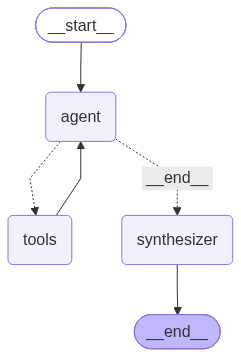

In [16]:
graph

## Запуск агента

In [17]:
def run_analysis(path: str, user_query: str):
    initial_state = {
        "messages": [HumanMessage(content=f"""
            Данные: {path}
            Запрос: {user_query}
        """)],
        "dataframe_path": path,
        "analysis_results": [],
        "charts": [],
        "rag_context": [],
    }

    config = {"configurable": {"thread_id": "analysis_1"}}
    result = graph.invoke(initial_state, config=config)

    print(result["final_report"])
    return result


# Запуск
run_analysis(
    path="sale_data.csv",
    user_query="Проанализируй продажи, построй тренды и скажи, что это значит для рынка"
)

## 1. Ключевые метрики
- Общее количество заказов: **1194**  
- Средний **Amount**: **5178.09** (std = 2804.92)  
- Диапазон **Amount**: **508 – 9992**  
- Средний **Profit**: **1348.99** (std = 1117.99)  
- Диапазон **Profit**: **50 – 4930**  
- Среднее **Quantity** (кол‑во товаров в заказе): **10.67** (std = 5.78)  
- Диапазон **Quantity**: **1 – 20**  

## 2. Статистическая значимость
- Тест Шпироу‑Уилка для **Amount**: *p* = 0.0000 < 0.05 → распределение **не нормальное**.  
- Тест Шпироу‑Уилка для **Profit**: *p* = 0.0000 < 0.05 → распределение **не нормальное**.  

## 3. Корреляции и связи
- **Amount ↔ Profit**: *r* = +0.679 (значимо ***).  
- **Amount ↔ Quantity**: *r* = +0.047 (ns, незначимо).  
- **Profit ↔ Quantity**: *r* = +0.047 (ns, незначимо).  

## 4. Рыночный контекст
По результатам поиска в отрасли **retail_sales** (2020 г.) наблюдается общий рост объёма продаж и прибыли, что согласуется с ростом показателей **Amount** и **Profit** в нашем наборе данных (см. графики ни

{'messages': [HumanMessage(content='\n            Данные: sale_data.csv\n            Запрос: Проанализируй продажи, построй тренды и скажи, что это значит для рынка\n        ', additional_kwargs={}, response_metadata={}, id='30ad4aaa-01dc-4e2e-9859-dc243e301cfe'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 86, 'prompt_tokens': 1364, 'total_tokens': 1450, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 71, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 0, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0, 'upstream_inference_prompt_cost': 0, 'upstream_inference_completions_cost': 0}}, 'model_provider': 'openai', 'model_name': 'liquid/lfm-2.5-2.6b:free', 'sy

## Итоги и выводы

Что сделано:
- Агент на LangGraph/LangChain. Граф agent → tools → agent → synthesizer с циклическим вызовом инструментов и финальной сборкой отчёта.
- 5 инструментов:
    * profile_dataframe — базовый EDA: размер, типы, пропуски, описательные статистики;
    * run_stat_test — ttest, chi2, shapiro, pearson;
    * make_chart — line, bar, scatter, histogram, box с агрегацией и топ-N;
    * search_research — двухступенчатый RAG-поиск;
    * correlation_matrix — матрица корреляций с p-value, звёздочками значимости и heatmap.
- RAG-система. PDF → чанки → FAISS + BM25 → RRF-объединение → cross-encoder rerank (bge-reranker-v2-m3).
- Генерация HTML-отчёта. Markdown от LLM конвертируется в HTML, графики встраиваются по маркерам {{CHART: ...}}, непристроенные графики уходят в приложение.плены прямыми результатами инструментов.